In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
scion_methods = ["constrained_scion", "unconstrained_scion"]
lr=0.1

Ls = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 
    # 4096
      ]
base_depth = Ls[0]
seeds = 50

scion_names={"constrained_scion": "Scion",
             "unconstrained_scion": "Unconstrained Scion",
             "projected_scion": "Projected Scion"}


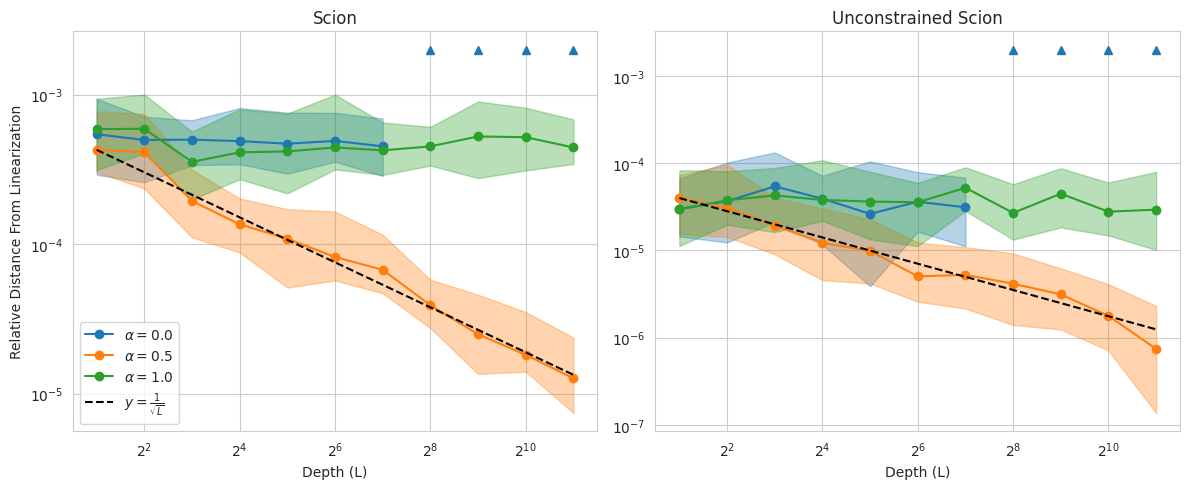

In [ ]:
sns.set_style('whitegrid')
colors = sns.color_palette("tab10") 

alpha0_color=colors[0]
alpha05_color=colors[1]
alpha1_color=colors[2]

colors = sns.color_palette("Set1")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axs = axes.ravel()

for i, scion_method in enumerate(scion_methods):
    delta_hs_1 =  np.load(f'lr_{lr}/{scion_method}_lr_{lr}_delta_hs_1.npy') # (n_seeds, n_depths_tested)
    delta_hs_05 = np.load(f'lr_{lr}/{scion_method}_lr_{lr}_delta_hs_05.npy') 
    delta_hs_0 =  np.load(f'lr_{lr}/{scion_method}_lr_{lr}_delta_hs_0.npy') 

    param_diff_1 =  np.load(f'lr_{lr}/{scion_method}_lr_{lr}_param_diff_1.npy') 
    param_diff_05 = np.load(f'lr_{lr}/{scion_method}_lr_{lr}_param_diff_05.npy')
    param_diff_0 =  np.load(f'lr_{lr}/{scion_method}_lr_{lr}_param_diff_0.npy')

    x = np.array(Ls, dtype=np.float32)
    y_alpha05 = np.median(delta_hs_05, axis=0)
    y_alpha05_first_quartile = np.quantile(delta_hs_05, q=0.25, axis=0)
    y_alpha05_third_quartile = np.quantile(delta_hs_05, q=0.75, axis=0)

    y_alpha1 = np.median(delta_hs_1, axis=0)
    y_alpha1_first_quartile = np.quantile(delta_hs_1, q=0.25, axis=0)
    y_alpha1_third_quartile = np.quantile(delta_hs_1, q=0.75, axis=0)

    y_sp_and_mup = np.median(delta_hs_0, axis=0)
    y_sp_and_mup_first_quartile = np.quantile(delta_hs_0, q=0.25, axis=0)
    y_sp_and_mup_third_quartile = np.quantile(delta_hs_0, q=0.75, axis=0)

    # y_alpha1 = (y_alpha05[0] / y_alpha1[0]) * y_alpha1
    # y_alpha1_first_quartile = (y_alpha05[0] / y_alpha1[0]) * y_alpha1_first_quartile
    # y_alpha1_third_quartile = (y_alpha05[0] / y_alpha1[0]) * y_alpha1_third_quartile

    # y_sp_and_mup = (y_alpha05[0] / y_sp_and_mup[0]) * y_sp_and_mup
    # y_sp_and_mup_first_quartile = (y_alpha05[0] / y_sp_and_mup[0]) * y_sp_and_mup_first_quartile
    # y_sp_and_mup_third_quartile = (y_alpha05[0] / y_sp_and_mup[0]) * y_sp_and_mup_third_quartile

    y_trend = (y_alpha05[0] * np.sqrt(x[0])) / np.sqrt(x)

    axs[i].plot(x, y_sp_and_mup, marker='o', label=r'$\alpha=0.0$', color=alpha0_color)
    axs[i].fill_between(x=x, y1=y_sp_and_mup_first_quartile, y2=y_sp_and_mup_third_quartile, color=alpha0_color, alpha=0.33)
    axs[i].plot(x[-4:], 4*[2e-3], marker='^', linestyle='none', color=alpha0_color) # Make sp_and_mup NaNs visible
    axs[i].plot(x, y_alpha05, marker='o', label=r'$\alpha=0.5$', color=alpha05_color)
    axs[i].fill_between(x=x, y1=y_alpha05_first_quartile, y2=y_alpha05_third_quartile, color=alpha05_color, alpha=0.33)
    axs[i].plot(x, y_alpha1, marker='o', label=r'$\alpha=1.0$', color=alpha1_color)
    axs[i].fill_between(x=x, y1=y_alpha1_first_quartile, y2=y_alpha1_third_quartile, color=alpha1_color, alpha=0.33)
    axs[i].plot(Ls, y_trend, linestyle='--', label=r'$y=\frac{1}{\sqrt{L}}$', color='black')

    axs[i].set_xscale('log', base=2)
    axs[i].set_yscale('log')
    axs[i].set_xlabel('Depth (L)')
    # axs[i].set_ylim(1e-7, 4e-3)
    if i==0:
        axs[i].set_ylabel('Relative Distance From Linearization')
        axs[i].legend()
    axs[i].set_title(f"{scion_names[scion_method]}")

    
plt.tight_layout()
plt.savefig(f'linearization_distance_lr_{lr}_scion_and_uscion.pdf')
plt.show()